# 単語ベクトルを 2 次元に落として可視化する

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/08_word_vectors/word_vectors_viz.ipynb)

NLP クックブック 08-06 ／ 単語ベクトル

単語ベクトルの空間で、似た単語が近くに集まっている様子を散布図で見たい。

In [1]:
!pip install -q gensim

In [2]:
import gensim.downloader as api
import numpy as np

wv = api.load("glove-wiki-gigaword-100")
groups = {
    "country": ["japan", "china", "france", "germany", "italy", "brazil", "india", "canada"],
    "city": ["tokyo", "beijing", "paris", "berlin", "rome", "london", "delhi", "ottawa"],
    "animal": ["cat", "dog", "horse", "lion", "tiger", "rabbit", "monkey", "elephant"],
    "food": ["sushi", "pizza", "bread", "rice", "noodles", "cheese", "apple", "banana"],
    "verb": ["run", "walk", "eat", "drink", "sleep", "write", "read", "speak"],
}
words = [w for ws in groups.values() for w in ws]
X = np.array([wv[w] for w in words])

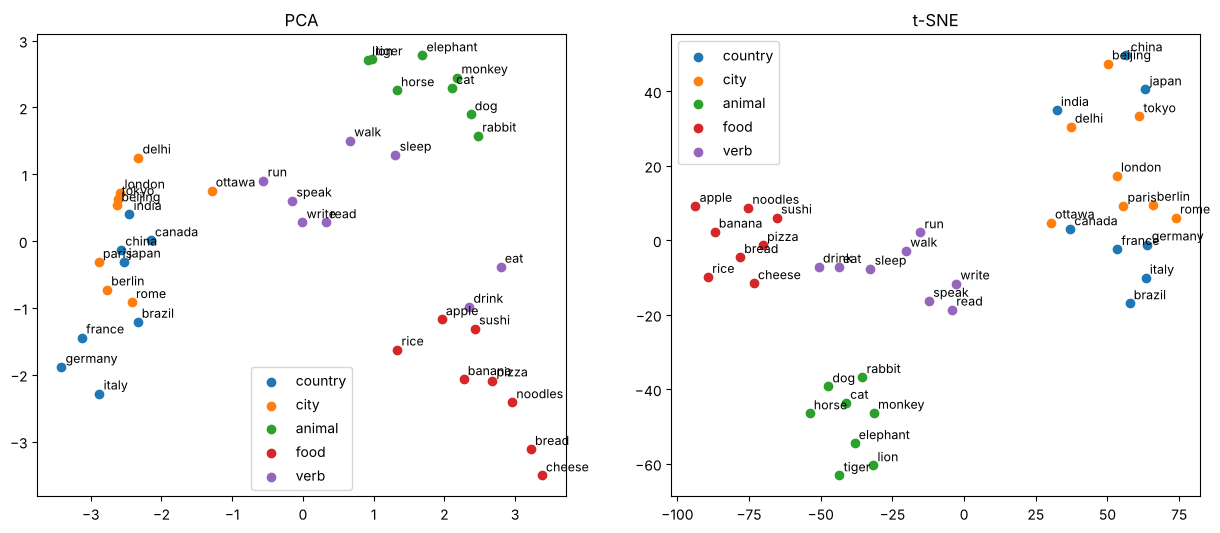

In [3]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (name, Z) in zip(axes, [("PCA", PCA(n_components=2).fit_transform(X)),
                                ("t-SNE", TSNE(n_components=2, perplexity=8, random_state=0).fit_transform(X))]):
    i = 0
    for label, ws in groups.items():
        ax.scatter(Z[i:i + len(ws), 0], Z[i:i + len(ws), 1], label=label)
        for j, w in enumerate(ws):
            ax.annotate(w, Z[i + j], fontsize=9, xytext=(3, 3), textcoords="offset points")
        i += len(ws)
    ax.set_title(name); ax.legend()
plt.show()

- PCA は大域的な構造 (国と首都が平行に並ぶなど) を保ち、t-SNE は近傍のまとまりを強調する。t-SNE の軸や距離に意味はない。
- 語数が多いときは t-SNE の `perplexity` を 30 前後に。数万語なら UMAP が速い。